IS_SOLD CLASSIFICATION - V3 (CROSS-VALIDATION)

 Data Loaded: (250, 8)

 Creating new features...
Features created

Features: 20
Samples: 250

CROSS-VALIDATION (10-Fold Stratified)

Random Forest:
  CV Scores: ['0.440', '0.520', '0.560', '0.400', '0.600', '0.440', '0.520', '0.400', '0.640', '0.520']
  Mean: 0.5040
  Std:  0.0784

Gradient Boosting:
  CV Scores: ['0.520', '0.600', '0.640', '0.520', '0.680', '0.400', '0.480', '0.480', '0.640', '0.520']
  Mean: 0.5480
  Std:  0.0840

XGBoost:
  CV Scores: ['0.520', '0.600', '0.560', '0.560', '0.640', '0.360', '0.440', '0.320', '0.520', '0.560']
  Mean: 0.5080
  Std:  0.0981

FINAL COMPARISON
               Model  CV Mean    CV Std
1  Gradient Boosting    0.548  0.084000
2            XGBoost    0.508  0.098061
0      Random Forest    0.504  0.078384

 Best Model: Gradient Boosting with CV Mean = 0.5480

Final Test Accuracy: 0.6200
              precision    recall  f1-score   support

    Not Sold       0.64      0.83      0.72        30
 

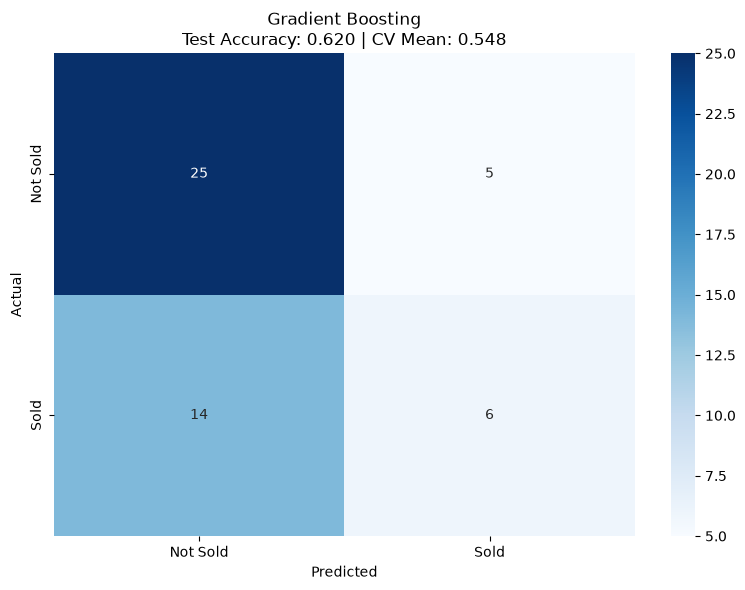

is_sold_confusion_matrix_v3.png saved
is_sold_classifier_final.pkl saved
is_sold_features_final.pkl saved

V3 - DONE  (BEST MODEL)


In [1]:
# File: 06_cross_validation.ipynb
# Version: V3 - Cross-Validation (FINAL)
# Author: Youssef
# ------------------------------------------------

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
warnings.filterwarnings('ignore')

print("=" * 60)
print("IS_SOLD CLASSIFICATION - V3 (CROSS-VALIDATION)")
print("=" * 60)

# ------------------------------------------------
# 1. Load Data

df = pd.read_csv('../../1_Data/cleaned_data.csv')   
df = df.drop('Property_ID', axis=1)
df['Is_Sold'] = df['Is_Sold'].map({'Yes': 1, 'No': 0})

print(f"\n Data Loaded: {df.shape}")

# ----------------------------------------------------
# 2. Feature Engineering

print("\n Creating new features...")

df['Total_Rooms'] = df['Bedrooms'] + df['Bathrooms']
df['Area_per_Bedroom'] = df['Area_SqM'] / df['Bedrooms']
df['Bathroom_Ratio'] = df['Bathrooms'] / df['Bedrooms']
df['Is_Luxury'] = ((df['Area_SqM'] > 300) & (df['Bedrooms'] >= 4)).astype(int)
df['Price_per_SqM'] = df['Price_EGP'] / df['Area_SqM']
df['Is_Expensive'] = (df['Price_per_SqM'] > df['Price_per_SqM'].median()).astype(int)
df['Days_Category'] = pd.cut(df['Days_On_Market'], bins=[0, 30, 90, 180], 
                              labels=['Fast', 'Medium', 'Slow'])

print(f"Features created")

# ----------------------------------------------------
# 3. Encoding

categorical_cols = ['Location', 'Property_Type', 'Days_Category']
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

# ----------------------------------------------------
# 4. Features & Target

X = df_encoded.drop('Is_Sold', axis=1)
y = df_encoded['Is_Sold']

print(f"\nFeatures: {X.shape[1]}")
print(f"Samples: {X.shape[0]}")

# ----------------------------------------------------
# 5. CROSS-VALIDATION (10-Fold Stratified) 

print("\n" + "=" * 60)
print("CROSS-VALIDATION (10-Fold Stratified)")
print("=" * 60)

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

models = {
    'Random Forest': RandomForestClassifier(
        n_estimators=300, max_depth=15, min_samples_split=5,
        min_samples_leaf=2, random_state=42, class_weight='balanced'
    ),
    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=200, learning_rate=0.05, max_depth=5, random_state=42
    ),
    'XGBoost': XGBClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=5,
        random_state=42, eval_metric='logloss',
        scale_pos_weight=(y == 0).sum() / (y == 1).sum()
    )
}

results = []
for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=cv, scoring='accuracy')
    print(f"\n{name}:")
    print(f"  CV Scores: {[f'{s:.3f}' for s in scores]}")
    print(f"  Mean: {scores.mean():.4f}")
    print(f"  Std:  {scores.std():.4f}")
    
    results.append({'Model': name, 'CV Mean': scores.mean(), 'CV Std': scores.std()})

# ----------------------------------------------------
# 6. Comparison

print("\n" + "=" * 60)
print("FINAL COMPARISON")
print("=" * 60)

results_df = pd.DataFrame(results).sort_values('CV Mean', ascending=False)
print(results_df)

best_name = results_df.iloc[0]['Model']
best_cv = results_df.iloc[0]['CV Mean']
print(f"\n Best Model: {best_name} with CV Mean = {best_cv:.4f}")

# ----------------------------------------------------
# 7. Train Final Model

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

best_model = models[best_name]
best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_test)
test_acc = accuracy_score(y_test, y_pred)

print(f"\nFinal Test Accuracy: {test_acc:.4f}")
print(classification_report(y_test, y_pred, target_names=['Not Sold', 'Sold']))

# ----------------------------------------------------
# 8. Confusion Matrix

plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not Sold', 'Sold'], yticklabels=['Not Sold', 'Sold'])
plt.title(f'{best_name}\nTest Accuracy: {test_acc:.3f} | CV Mean: {best_cv:.3f}')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.savefig('is_sold_confusion_matrix_v3.png', dpi=150, bbox_inches='tight')
plt.show()
print("is_sold_confusion_matrix_v3.png saved")

# -----------------------------------------------------
# 9. Save Best Model

joblib.dump(best_model, 'is_sold_classifier_final.pkl')
joblib.dump(X.columns.tolist(), 'is_sold_features_final.pkl')
print("is_sold_classifier_final.pkl saved")
print("is_sold_features_final.pkl saved")

print("\n" + "=" * 60)
print("V3 - DONE  (BEST MODEL)")
print("=" * 60)